In [13]:
import json
import os
import shutil
import threading
import time
from datetime import datetime, timezone

import requests
import matplotlib.pyplot as plt
from IPython.display import display

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import (
    StructType, StructField, StringType, IntegerType, DoubleType
)

In [14]:
try:
    SparkSession.getActiveSession().stop()
except Exception:
    pass

In [15]:
URL_BASE_API = "http://192.168.122.92:5000/api/tabelas"

URL_VENDAS = f"{URL_BASE_API}/vendas"
URL_ESTOQUE = f"{URL_BASE_API}/estoque"
URL_CLIENTES = f"{URL_BASE_API}/clientes"
URL_VENDEDORES = f"{URL_BASE_API}/vendedores"
URL_CREDIARIO = f"{URL_BASE_API}/crediario"
URL_PROMOCOES = f"{URL_BASE_API}/promocoes"

try:
    resposta = requests.get(URL_VENDAS, timeout=30)
    resposta.raise_for_status()
    dados_vendas = resposta.json()
    print("Total de vendas retornadas da API:", len(dados_vendas))
    print("Exemplo de registro retornado:")
    print(json.dumps(dados_vendas[0], indent=2))
except Exception as e:
    print("Aviso de conexão com a API:", e)

Total de vendas retornadas da API: 14806
Exemplo de registro retornado:
{
  "canal": "F\u00edsica",
  "categoria": "Acess\u00f3rio",
  "cor": "Verde",
  "data_venda": "2026-04-03",
  "desconto": 0.0,
  "forma_pagamento": "Cart\u00e3o de D\u00e9bito",
  "hora_venda": "12:15",
  "id_cliente": NaN,
  "id_produto": 48,
  "id_venda": 1,
  "id_vendedor": 13,
  "preco_unitario": 266.71,
  "produto": "Acess\u00f3rio X",
  "quantidade": 1,
  "tamanho": "GG",
  "valor_total": 266.71
}


In [16]:
spark = SparkSession.builder \
    .appName("Spark_Streaming_Vendas_DB") \
    .config("spark.driver.extraJavaOptions", 
            "--add-opens=java.base/java.nio=ALL-UNNAMED --add-opens=java.base/sun.nio.ch=ALL-UNNAMED") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")

In [17]:
PASTA_BASE = "./vendas_db_stream"
PASTA_ENTRADA = f"{PASTA_BASE}/entrada"
PASTA_TEMPORARIOS = f"{PASTA_BASE}/temporarios"
PASTA_CHECKPOINT = f"{PASTA_BASE}/checkpoint"

shutil.rmtree(PASTA_BASE, ignore_errors=True)

os.makedirs(PASTA_ENTRADA, exist_ok=True)
os.makedirs(PASTA_TEMPORARIOS, exist_ok=True)

print("Diretório monitorado pelo Spark Streaming:", PASTA_ENTRADA)

Diretório monitorado pelo Spark Streaming: ./vendas_db_stream/entrada


In [18]:
esquema_vendas = StructType([
    StructField('coleta', IntegerType()),
    StructField('instante', StringType()),
    StructField('id_venda', IntegerType()),
    StructField('data_venda', StringType()),
    StructField('hora_venda', StringType()),
    StructField('id_cliente', IntegerType()),
    StructField('id_vendedor', IntegerType()),
    StructField('id_produto', IntegerType()),
    StructField('produto', StringType()),
    StructField('categoria', StringType()),
    StructField('cor', StringType()),
    StructField('tamanho', StringType()),
    StructField('quantidade', IntegerType()),
    StructField('preco_unitario', DoubleType()),
    StructField('desconto', DoubleType()),
    StructField('valor_total', DoubleType()),
    StructField('forma_pagamento', StringType()),
    StructField('canal', StringType())
])

df_stream = spark.readStream.schema(esquema_vendas).json(PASTA_ENTRADA)

In [19]:
vendas_classificadas = df_stream.withColumn(
    "classificacao_desconto",
    F.when(F.col("desconto") > 0.15, "Alto Desconto")
    .when(F.col("desconto") > 0.0, "Com Desconto")
    .otherwise("Sem Desconto")
).withColumn(
    "tipo_canal",
    F.when(F.col("canal") == "Online", "Digital")
    .otherwise("Presencial")
)

vendas_classificadas.printSchema()

root
 |-- coleta: integer (nullable = true)
 |-- instante: string (nullable = true)
 |-- id_venda: integer (nullable = true)
 |-- data_venda: string (nullable = true)
 |-- hora_venda: string (nullable = true)
 |-- id_cliente: integer (nullable = true)
 |-- id_vendedor: integer (nullable = true)
 |-- id_produto: integer (nullable = true)
 |-- produto: string (nullable = true)
 |-- categoria: string (nullable = true)
 |-- cor: string (nullable = true)
 |-- tamanho: string (nullable = true)
 |-- quantidade: integer (nullable = true)
 |-- preco_unitario: double (nullable = true)
 |-- desconto: double (nullable = true)
 |-- valor_total: double (nullable = true)
 |-- forma_pagamento: string (nullable = true)
 |-- canal: string (nullable = true)
 |-- classificacao_desconto: string (nullable = false)
 |-- tipo_canal: string (nullable = false)



In [20]:
consulta = (
    vendas_classificadas.writeStream
    .format("memory")
    .queryName("vendas")
    .outputMode("append")
    .option("checkpointLocation", PASTA_CHECKPOINT)
    .trigger(processingTime="5 seconds")
    .start()
)

print("Structured Streaming ativo?", consulta.isActive)

Structured Streaming ativo? True


In [ ]:
INTERVALO_SEGUNDOS = 30
parar_coleta = threading.Event()
numero_coleta = 0

def coletar():
    global numero_coleta

    # Requisita a tabela de vendas servida no endpoint HTTP
    resposta = requests.get(URL_VENDAS, timeout=30)
    resposta.raise_for_status()
    registros = resposta.json()

    proxima_coleta = numero_coleta + 1
    instante = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S")

    arquivo_nome = f"vendas_coleta_{proxima_coleta:05d}.json"
    caminho_temporario = os.path.join(PASTA_TEMPORARIOS, arquivo_nome)
    caminho_final = os.path.join(PASTA_ENTRADA, arquivo_nome)

    with open(caminho_temporario, "w", encoding="utf-8") as arquivo:
        for reg in registros:
            id_cli = reg.get("id_cliente")
            dado = {
                "coleta": proxima_coleta,
                "instante": instante,
                "id_venda": int(reg.get("id_venda", 0)),
                "data_venda": str(reg.get("data_venda", "")),
                "hora_venda": str(reg.get("hora_venda", "")),
                "id_cliente": int(id_cli) if id_cli is not None and str(id_cli).replace('.','',1).isdigit() else None,
                "id_vendedor": int(reg.get("id_vendedor", 0)),
                "id_produto": int(reg.get("id_produto", 0)),
                "produto": str(reg.get("produto", "")),
                "categoria": str(reg.get("categoria", "")),
                "cor": str(reg.get("cor", "")),
                "tamanho": str(reg.get("tamanho", "")),
                "quantidade": int(reg.get("quantidade", 0)),
                "preco_unitario": float(reg.get("preco_unitario", 0.0)),
                "desconto": float(reg.get("desconto", 0.0)),
                "valor_total": float(reg.get("valor_total", 0.0)),
                "forma_pagamento": str(reg.get("forma_pagamento", "")),
                "canal": str(reg.get("canal", ""))
            }
            arquivo.write(json.dumps(dado, ensure_ascii=False) + "\n")

    os.replace(caminho_temporario, caminho_final)
    numero_coleta = proxima_coleta
    print(f"Coleta {numero_coleta}: {len(registros)} registros ingeridos às {instante} (UTC)")

def executar_coleta_automatica():
    while not parar_coleta.is_set():
        try:
            coletar()
        except (requests.RequestException, ValueError, OSError, KeyError) as erro:
            print("Falha na coleta da API:", erro)

        if parar_coleta.wait(INTERVALO_SEGUNDOS):
            break

if "tarefa_coleta" not in globals() or not tarefa_coleta.is_alive():
    parar_coleta.clear()
    tarefa_coleta = threading.Thread(target=executar_coleta_automatica, daemon=True)
    tarefa_coleta.start()

print("Coleta em segundo plano ativa?", tarefa_coleta.is_alive())

Coleta em segundo plano ativa? True


Coleta 1: 14806 registros ingeridos às 2026-11-08 13:48:08 (UTC)


--- RESULTADOS DA COLETA 1 ---
Hora do snapshot (UTC): 2026-11-08 13:48:08


/home/marcos/.local/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/marcos/.local/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,Total de Vendas,Unidades Vendidas,Faturamento Total (R$),Ticket Medio (R$),Vendas Online,Vendas Fisicas
0,14806,44501,8142703.72,549.96,7387,7419


/home/marcos/.local/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/marcos/.local/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


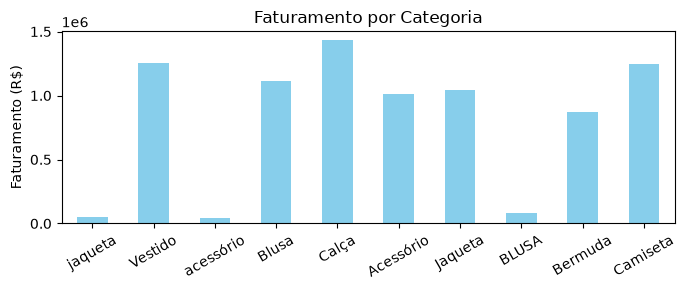

/home/marcos/.local/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/marcos/.local/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


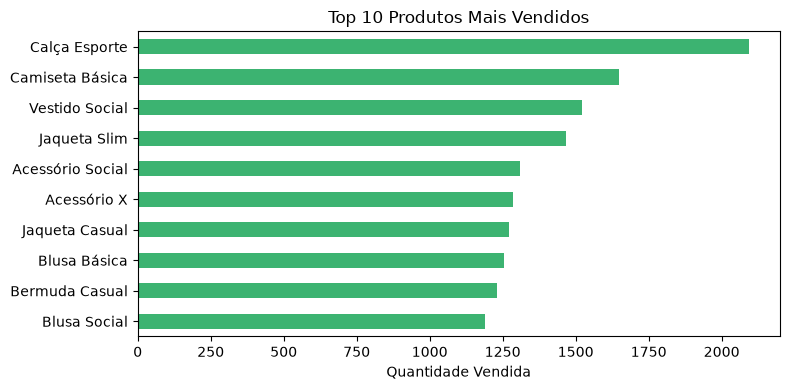

Coleta 2: 14806 registros ingeridos às 2026-11-08 13:48:38 (UTC)
Coleta 3: 14806 registros ingeridos às 2026-11-08 13:49:09 (UTC)


In [ ]:
def mostrar_resultados():
    ultima_coleta = spark.sql("SELECT MAX(coleta) AS numero FROM vendas").first()["numero"]

    if ultima_coleta is None:
        print("Ainda não há dados processados no Spark. Aguarde alguns segundos.")
        return

    # Filtra os dados da última coleta
    atual = spark.sql(f"SELECT * FROM vendas WHERE coleta = {ultima_coleta}")

    resumo = atual.agg(
        F.count("*").alias("Total de Vendas"),
        F.sum("quantidade").alias("Unidades Vendidas"),
        F.round(F.sum("valor_total"), 2).alias("Faturamento Total (R$)"),
        F.round(F.avg("valor_total"), 2).alias("Ticket Medio (R$)"),
        F.sum(F.when(F.col("canal") == "Online", 1).otherwise(0)).alias("Vendas Online"),
        F.sum(F.when(F.col("canal") == "Física", 1).otherwise(0)).alias("Vendas Fisicas")
    )

    print(f"--- RESULTADOS DA COLETA {ultima_coleta} ---")
    print("Hora do snapshot (UTC):", atual.select("instante").first()["instante"])
    display(resumo.toPandas())

    cat_df = atual.groupBy("categoria").agg(F.sum("valor_total").alias("faturamento")).toPandas()
    cat_df.plot.bar(x="categoria", y="faturamento", legend=False, figsize=(7, 3), color="skyblue")
    plt.title("Faturamento por Categoria")
    plt.xlabel("")
    plt.ylabel("Faturamento (R$)")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

    # Visualização 2: Top 10 Produtos por Quantidade Vendida
    top_prod = atual.groupBy("produto").agg(F.sum("quantidade").alias("qtd")).orderBy(F.desc("qtd")).limit(10).toPandas()
    top_prod.sort_values("qtd").plot.barh(x="produto", y="qtd", legend=False, figsize=(8, 4), color="mediumseagreen")
    plt.title("Top 10 Produtos Mais Vendidos")
    plt.xlabel("Quantidade Vendida")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

mostrar_resultados()

In [23]:
parar_coleta.set()

if "tarefa_coleta" in globals():
    tarefa_coleta.join(timeout=35)

# Interrompe o streaming e encerra a sessão Spark
consulta.stop()
spark.stop()

print("Coleta em segundo plano ativa?", tarefa_coleta.is_alive() if "tarefa_coleta" in globals() else False)
print("Structured Streaming ativo?", consulta.isActive)

Coleta em segundo plano ativa? False
Structured Streaming ativo? False
